# Chapter 9 — Experimental comparison

Chapter 8 ended with development-set numbers. A method that was *designed* on some data will look good on that data. This chapter asks the only question that counts: does it hold on labels that played no role in any decision?

## 9.1 The design of the experiment

| | |
|---|---|
| **Controlled** | labels and ground truth; the candidate pool (recorded once per label from the original retrieval); the evidence about each candidate; the split |
| **Manipulated** | how the pool is *ranked*: original $f_q$, $f_c$, $f_c+f_d$; each hypothesis alone; the combined method; ablations |
| **Measured** | hit@1 (primary), hit@3, hit@5, MRR |
| **Development set** | MS COCO (80) + one half of the Visual Genome sample — all choices made here |
| **Test set** | the other half of the Visual Genome sample — used once |
| **Uncertainty** | Wilson 95 % interval per method; for differences, a **paired** bootstrap interval and the exact McNemar test |

**Why paired?** Both methods are evaluated on the *same* labels. Many labels are easy for both or impossible for both and say nothing about the difference. McNemar's test looks only at the labels where the methods disagree: if method B wins $b$ of them and method A wins $a$, then under “no difference” $b \sim \mathrm{Binomial}(a+b, \tfrac12)$. This is far more sensitive than comparing two separate confidence intervals.

**Why is the recorded pool a fair control?** Because every method sees exactly the entities the original retrieval returned, with the same link counts, classes and descriptions; the improved method gets no extra retrieval budget. A test in the repository checks that this offline harness reproduces the stored results of the reproduction label by label.

In [1]:
# Locate the research/ directory and make the real implementation importable.
import sys, json
from pathlib import Path
RESEARCH = Path.cwd().resolve()
while not (RESEARCH / "pel").is_dir():
    RESEARCH = RESEARCH.parent
for path in (RESEARCH, RESEARCH / "experiments"):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))
FIGURES = RESEARCH / "experiments" / "figures"
RESULTS = RESEARCH / "experiments" / "results"
%matplotlib inline
from IPython.display import Image
report = json.loads((RESULTS / "improvements" / "analysis_L_links.json").read_text())
report_s = json.loads((RESULTS / "improvements" / "analysis_S_links.json").read_text())
print("test-set sizes:", report["test_n"], "| development:", report["development_n"])
print("selected on development:", {k: round(v, 1) for k, v in report["selected_on_development"]["weights"].items()},
      report["selected_on_development"]["inventory"])

test-set sizes: {'wikidata': 300, 'dbpedia': 83, 'yago': 300} | development: {'wikidata': 380, 'dbpedia': 147, 'yago': 380}
selected on development: {'name': 0.2, 'type': 0.1, 'gloss': 0.3, 'popularity': 0.4} physical


## 9.2 Test-set results (candidate pools of the `L_links` query)

In [2]:
def table(rep, split="test"):
    kgs = rep["knowledge_graphs"]
    names = [n for n in rep[split][kgs[0]]["methods"] if not n.startswith("original ") and "−" not in n and "toggled" not in n]
    print(f"{'hit@1 [95 % CI]':40s}" + "".join(f"{kg + ' (n=' + str(rep[split + '_n'][kg]) + ')':>24s}" for kg in kgs))
    for name in names:
        cells = [rep[split][kg]["methods"][name] for kg in kgs]
        print(f"{name:40s}" + "".join(f"{c['hit@1']:.3f} [{c['hit@1_ci95'][0]:.2f}, {c['hit@1_ci95'][1]:.2f}]".rjust(24) for c in cells))
    best = rep["best_of_12_original_on_development"]
    print(f"{'best of the 12 original conditions':40s}" + "".join(
        f"{rep[split][kg]['methods']['original ' + best[kg]]['hit@1']:.3f} ({best[kg]})".rjust(24) for kg in kgs))
table(report)

hit@1 [95 % CI]                                 wikidata (n=300)          dbpedia (n=83)            yago (n=300)
fq                                            0.557 [0.50, 0.61]      0.578 [0.47, 0.68]      0.500 [0.44, 0.56]
fc                                            0.583 [0.53, 0.64]      0.651 [0.54, 0.74]      0.623 [0.57, 0.68]
fc+fd                                         0.423 [0.37, 0.48]      0.651 [0.54, 0.74]      0.203 [0.16, 0.25]
H1 directed hypernym score                    0.563 [0.51, 0.62]      0.651 [0.54, 0.74]      0.587 [0.53, 0.64]
H2 noun senses                                0.433 [0.38, 0.49]      0.651 [0.54, 0.74]      0.210 [0.17, 0.26]
H2 physical senses                            0.430 [0.38, 0.49]      0.651 [0.54, 0.74]      0.200 [0.16, 0.25]
H4 gloss overlap (replaces type)              0.517 [0.46, 0.57]      0.651 [0.54, 0.74]      0.557 [0.50, 0.61]
H5 class-label word back-off                  0.467 [0.41, 0.52]      0.639 [0.53, 0.73]      0.

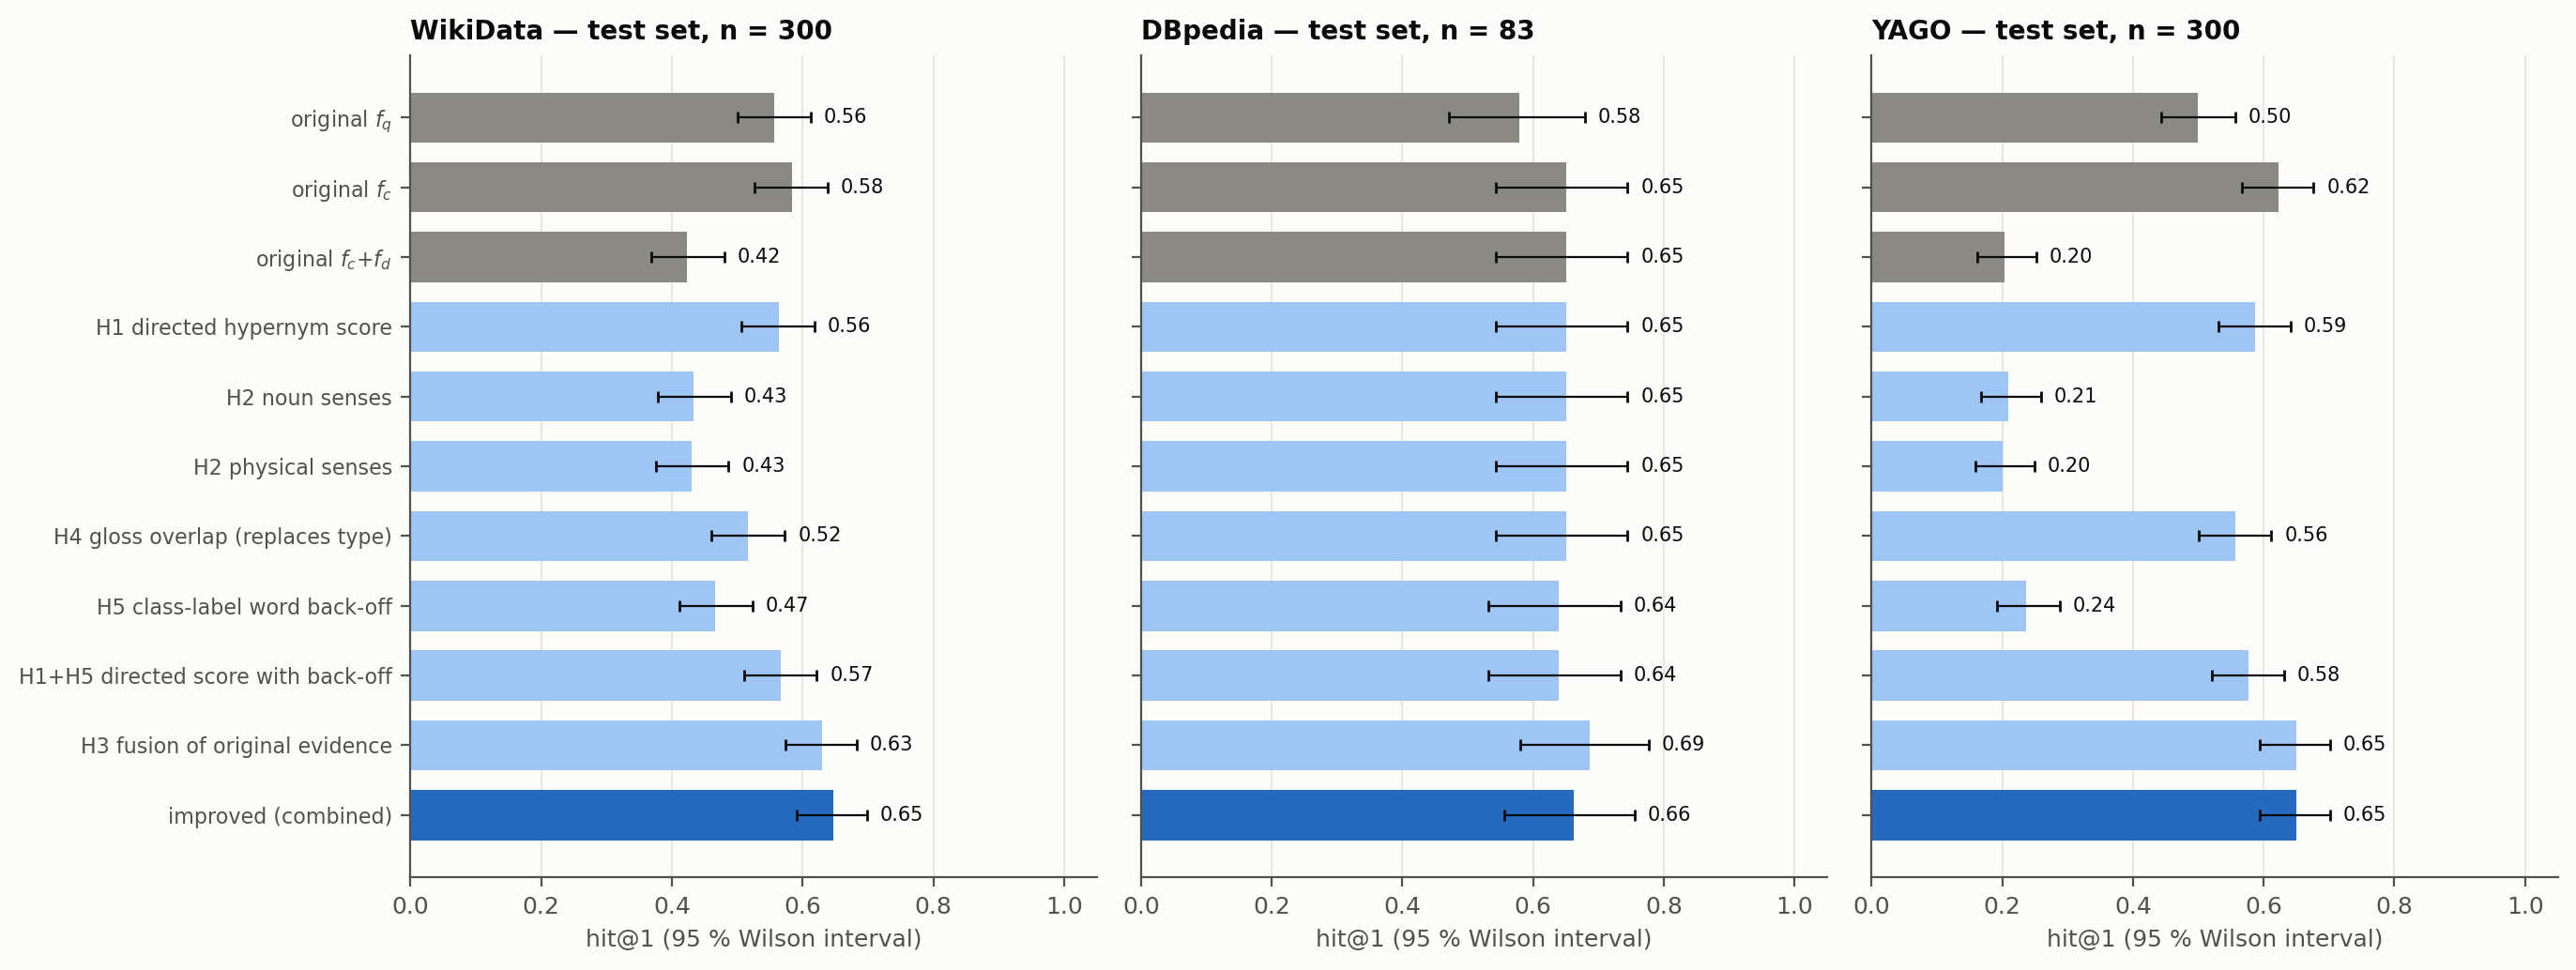

In [3]:
Image(filename=str(FIGURES / "improvements" / "methods_hit1_test.png"), width=1000)

*Test set. Grey: original processes. Light blue: one change applied to the original $f_c+f_d$. Dark blue: combined method. Bars are 95 % Wilson intervals.*

First reading:

* The original $f_c + f_d$ is the outlier on WikiData and YAGO — far below simply taking the pool order ($f_c$).
* **H1** alone lifts it back to about the level of $f_c$. On DBpedia nothing changes.
* **H2** (noun or physical senses) is indistinguishable from the original everywhere — including DBpedia, where the development set had suggested a gain.
* **H3** (fusion) and the **combined** method lead on all three graphs, but look at the intervals: they overlap those of the best original process.

Overlapping intervals do not settle the matter — the comparison is paired:

## 9.3 Is the difference real?

In [4]:
def comparisons(rep):
    for kg in rep["knowledge_graphs"]:
        print(kg)
        for name, c in rep["test"][kg]["comparisons"].items():
            print(f"   {name:58s} Δ = {c['difference']:+.3f} [{c['difference_ci95'][0]:+.3f}, {c['difference_ci95'][1]:+.3f}]"
                  f"   wins {c['b_wins']:3d} : {c['a_wins']:<3d}  p = {c['mcnemar_exact_p']:.4f}")
comparisons(report)

wikidata
   full vs fc+fd                                              Δ = +0.223 [+0.170, +0.277]   wins  75 : 8    p = 0.0000
   full vs best original (fq)                                 Δ = +0.090 [+0.050, +0.133]   wins  35 : 8    p = 0.0000
   full vs best of 12 original conditions (S_links|fq)        Δ = +0.037 [-0.020, +0.093]   wins  44 : 33   p = 0.2543
   H1 directed hypernym score vs fc+fd                        Δ = +0.140 [+0.093, +0.187]   wins  50 : 8    p = 0.0000
   H2 noun senses vs fc+fd                                    Δ = +0.010 [-0.010, +0.030]   wins   6 : 3    p = 0.5078
   H2 physical senses vs fc+fd                                Δ = +0.007 [-0.013, +0.030]   wins   6 : 4    p = 0.7539
   H4 gloss overlap (replaces type) vs fc+fd                  Δ = +0.093 [+0.043, +0.147]   wins  49 : 21   p = 0.0011
   H5 class-label word back-off vs fc+fd                      Δ = +0.043 [+0.007, +0.077]   wins  21 : 8    p = 0.0241
   H1+H5 directed score with back-off v

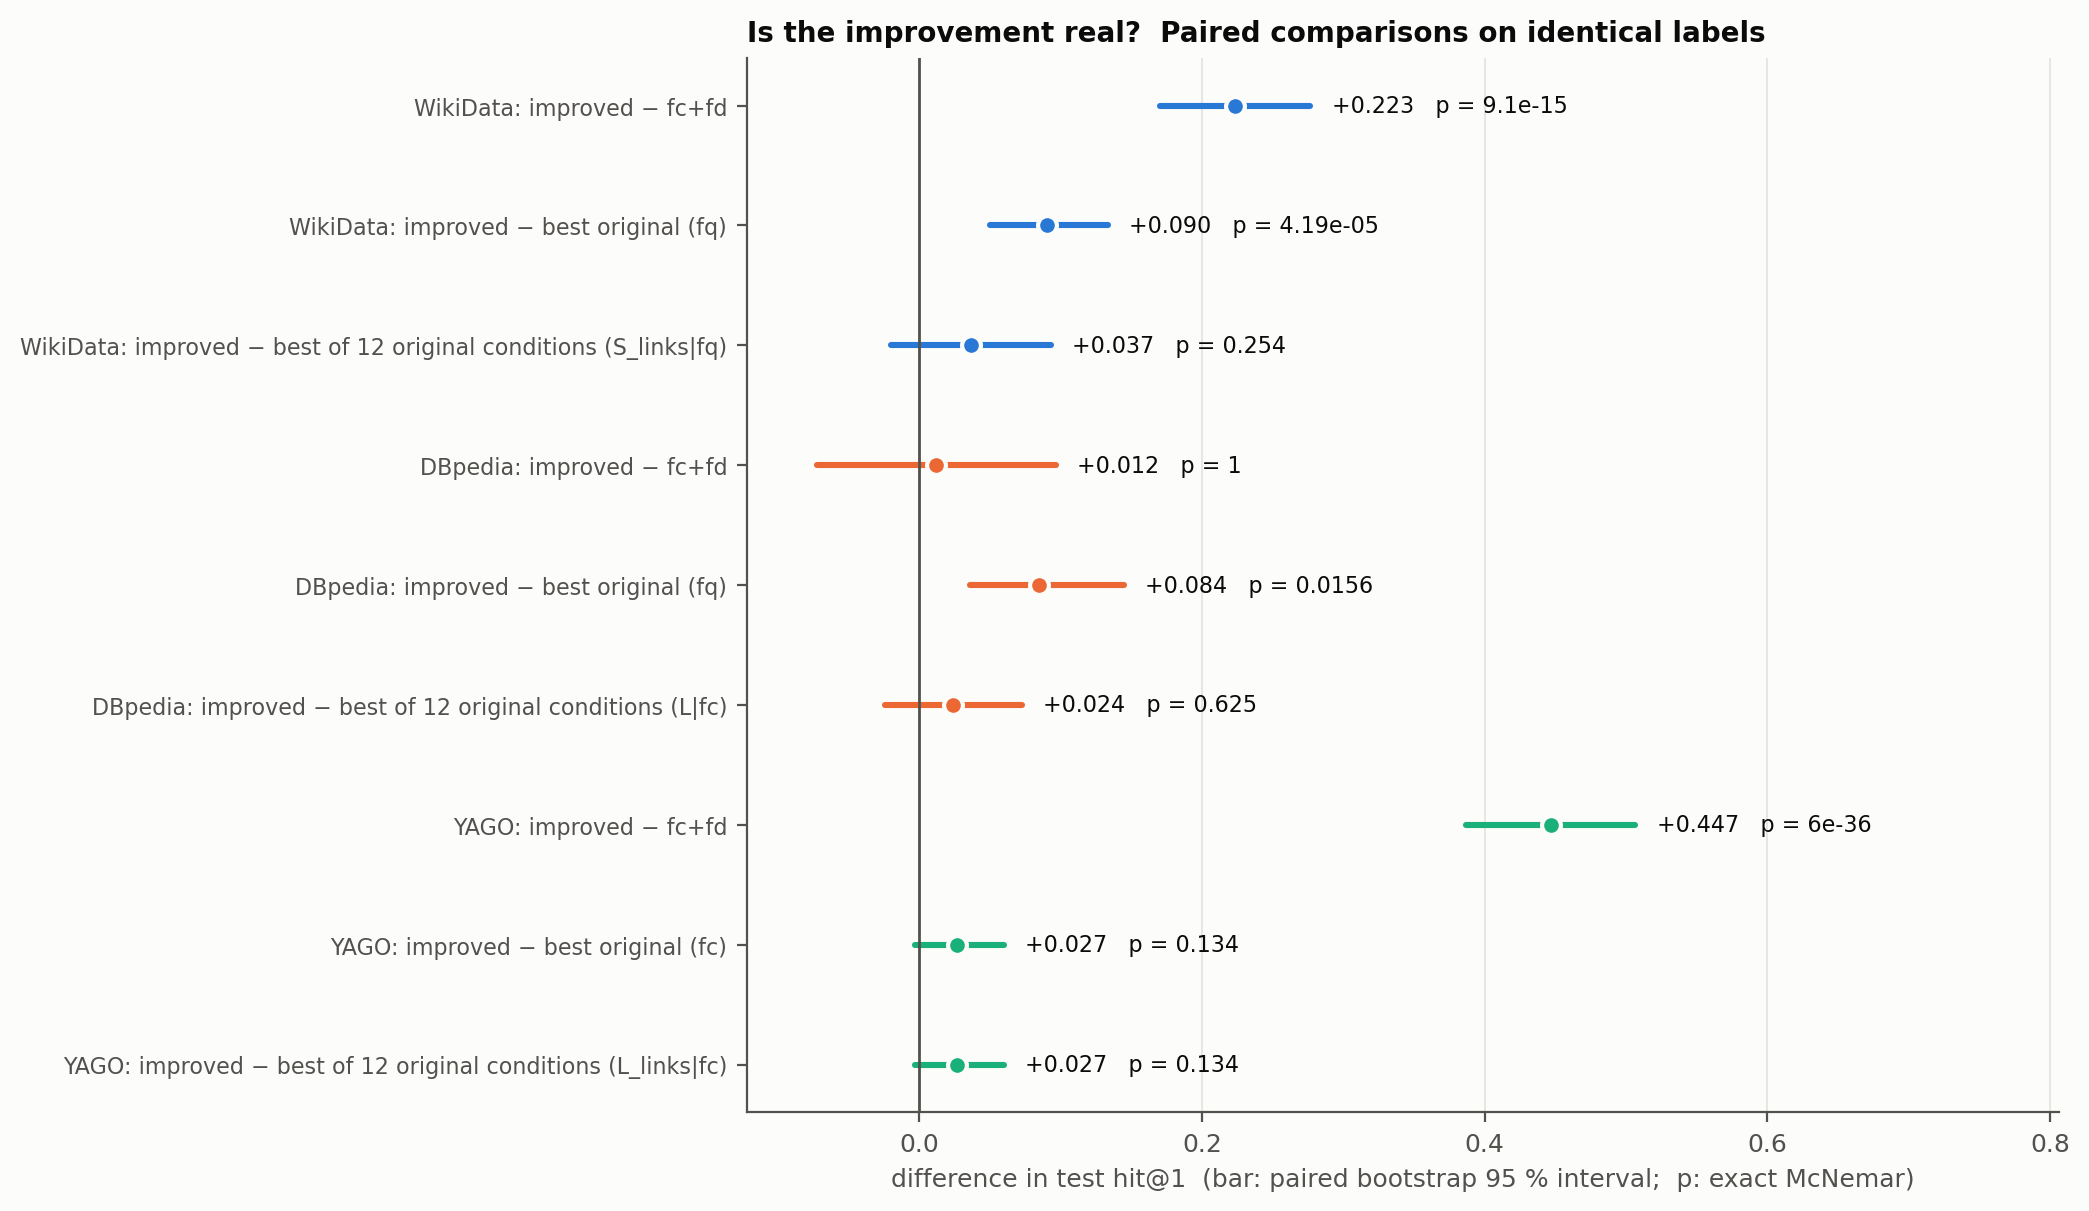

In [5]:
Image(filename=str(FIGURES / "improvements" / "paired_differences_test.png"), width=950)

Three levels of claim, in decreasing strength:

1. **Against the original disambiguation ($f_c+f_d$).** On WikiData and YAGO the combined method wins by 22 and 45 points; the intervals are far from zero. On DBpedia there is no difference. *This is solid:* Algorithm 2 as published is harmful on two of three graphs today, and the repair works.
2. **Against the best original process on the same pool.** A gain of a few points on each graph (the comparison process was fixed on development data).
3. **Against the best of all twelve original conditions** (any query type, any process, chosen on development data). The combined method is ahead on every graph, by two to four points, and **none of these differences is statistically significant**.

The third level is the honest yardstick for “is the improved method better than what the paper already had?”, and on these pools the answer is: *not demonstrably*.

## 9.4 A second pool: the `S_links` query

On WikiData the strongest original condition uses the `S_links` query (which also matches aliases). The same analysis, repeated on `S_links` pools (WikiData and YAGO; not recorded for DBpedia):

In [6]:
table(report_s)
print()
comparisons(report_s)

hit@1 [95 % CI]                                 wikidata (n=300)            yago (n=300)
fq                                            0.610 [0.55, 0.66]      0.513 [0.46, 0.57]
fc                                            0.560 [0.50, 0.62]      0.567 [0.51, 0.62]
fc+fd                                         0.350 [0.30, 0.41]      0.200 [0.16, 0.25]
H1 directed hypernym score                    0.587 [0.53, 0.64]      0.540 [0.48, 0.60]
H2 noun senses                                0.363 [0.31, 0.42]      0.203 [0.16, 0.25]
H2 physical senses                            0.357 [0.30, 0.41]      0.193 [0.15, 0.24]
H4 gloss overlap (replaces type)              0.390 [0.34, 0.45]      0.473 [0.42, 0.53]
H5 class-label word back-off                  0.370 [0.32, 0.43]      0.210 [0.17, 0.26]
H1+H5 directed score with back-off            0.580 [0.52, 0.63]      0.513 [0.46, 0.57]
H3 fusion of original evidence                0.627 [0.57, 0.68]      0.607 [0.55, 0.66]
full (combined)      

On the richer WikiData pool the combined method gains about six points over the best original condition, with an interval that excludes zero; on YAGO the difference is nil.

**A caution about multiplicity.** “Combined vs. best of twelve” has now been tested in five graph–pool settings. With five tests, one $p$-value near 0.01 is not surprising evidence: the Holm-corrected threshold for the smallest of five is $0.05/5 = 0.01$, and the smallest $p$ here is slightly above it. So the summary across all settings is: *the improved method is never worse and may be a few points better; a robust gain over the best original condition is not established.*

## 9.5 Which ingredient does the work? (ablation)

L_links wikidata  combined 0.647 | −H1 (symmetric similarity): -0.010  −H2 (all senses): +0.007  −type evidence: +0.000  −gloss evidence (H4): -0.017  −popularity: -0.110  −name similarity: -0.027
L_links dbpedia   combined 0.663 | −H1 (symmetric similarity): -0.024  −H2 (all senses): +0.012  −type evidence: -0.024  −gloss evidence (H4): +0.000  −popularity: -0.024  −name similarity: +0.000
L_links yago      combined 0.650 | −H1 (symmetric similarity): -0.003  −H2 (all senses): +0.007  −type evidence: -0.007  −gloss evidence (H4): -0.027  −popularity: -0.143  −name similarity: -0.023
S_links wikidata  combined 0.673 | −H1 (symmetric similarity): -0.040  −H2 (all senses): +0.020  −type evidence: -0.027  −gloss evidence (H4): -0.023  −popularity: -0.180  −name similarity: -0.023
S_links yago      combined 0.627 | −H1 (symmetric similarity): -0.010  −H2 (all senses): +0.003  −type evidence: +0.003  −gloss evidence (H4): -0.010  −popularity: -0.170  −name similarity: -0.010


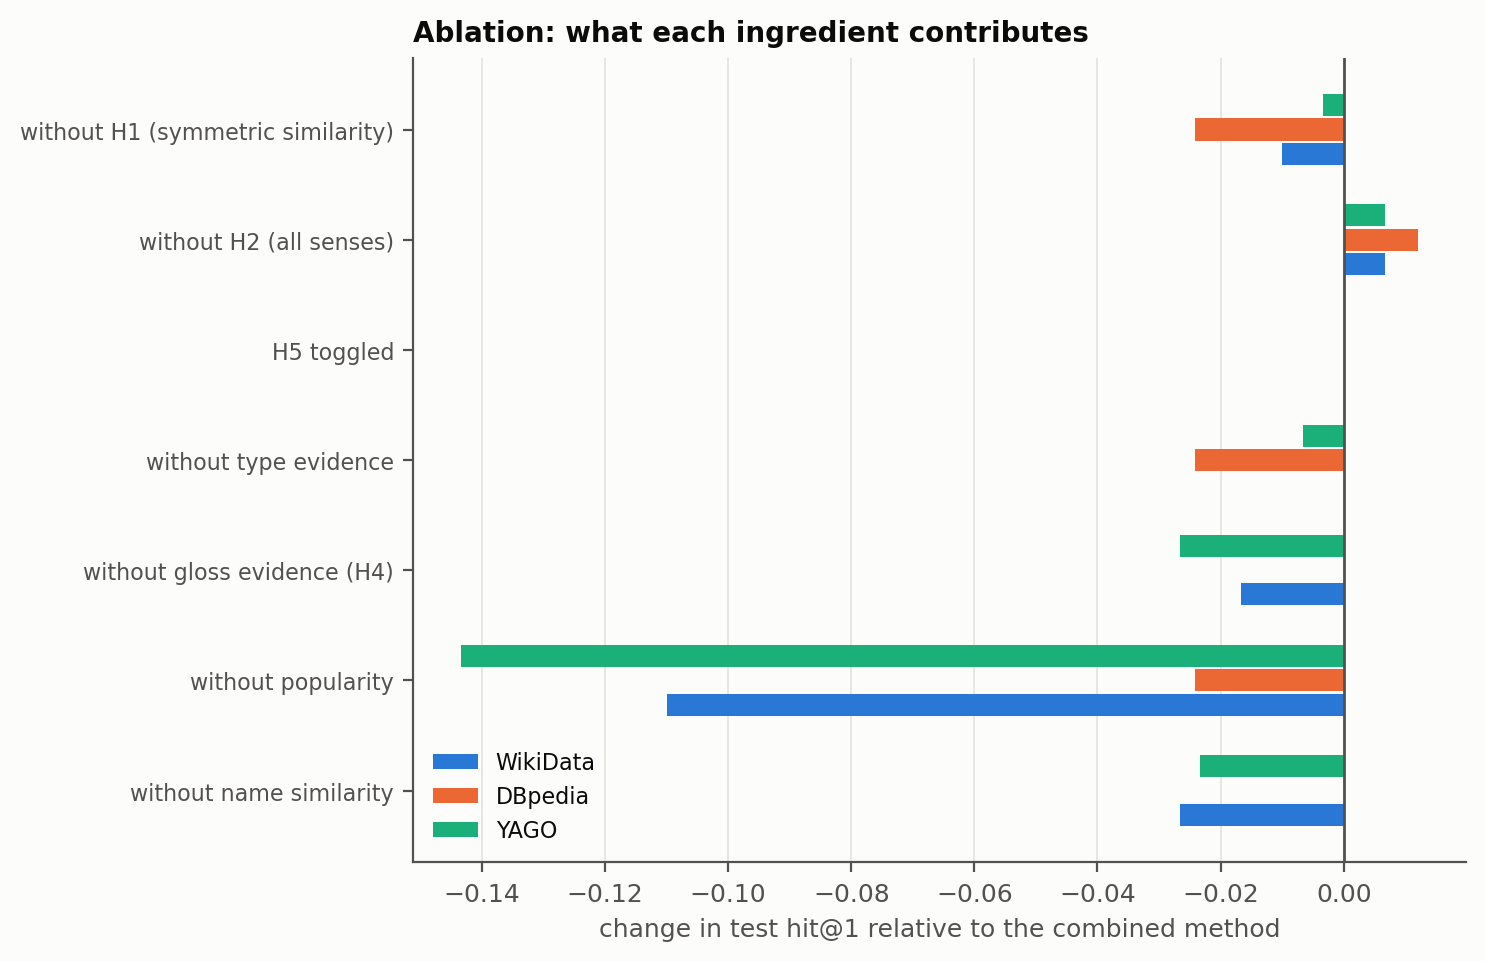

In [7]:
def ablation(rep, tag):
    for kg in rep["knowledge_graphs"]:
        methods = rep["test"][kg]["methods"]
        full = methods["full (combined)"]["hit@1"]
        print(f"{tag} {kg:9s} combined {full:.3f} | " + "  ".join(
            f"{name.replace('full − ', '−').replace('full, ', '')}: {m['hit@1'] - full:+.3f}"
            for name, m in methods.items() if "−" in name))
ablation(report, "L_links"); ablation(report_s, "S_links")
Image(filename=str(FIGURES / "improvements" / "ablation_test.png"), width=750)

*Change in test hit@1 when one ingredient is removed from the combined method (nothing re-tuned). Bars to the left: the ingredient helps.*

* **Popularity** is by far the most important evidence on WikiData and YAGO.
* **H1** and **H4** each contribute a little (one to four points); individually within noise.
* **H2** points the *wrong way* in all five settings: the combined method would have been slightly better without the sense restriction. It was selected on the development set by a small margin that did not transfer. **H2 is rejected.**

## 9.6 What re-ranking can and cannot do

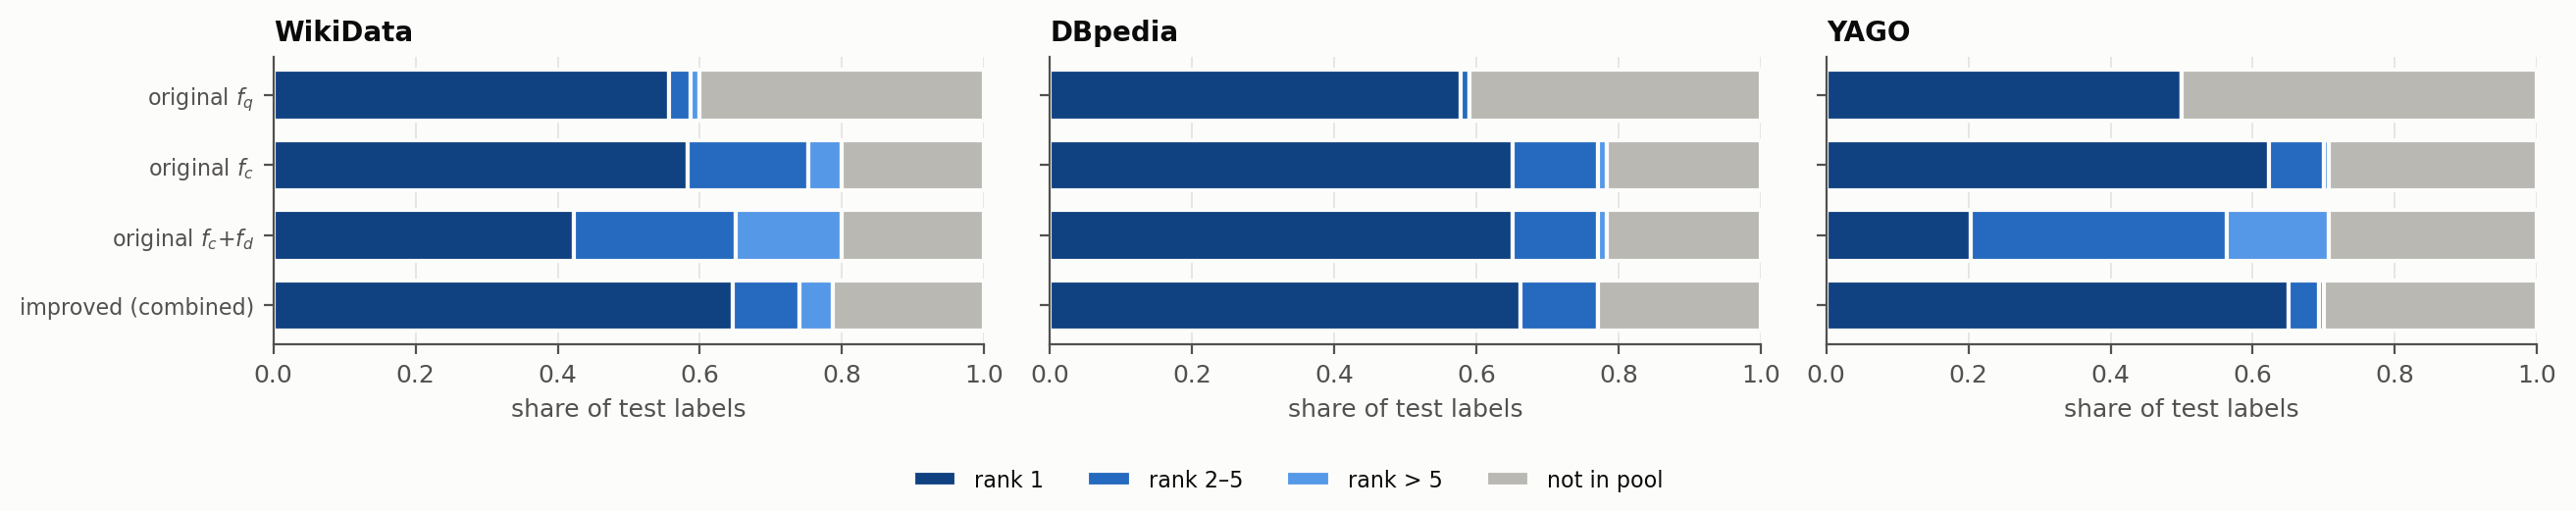

In [8]:
Image(filename=str(FIGURES / "improvements" / "rank_of_correct_entity_test.png"), width=1000)

*Where the correct entity ends up (test set). Dark: rank 1. Grey: not in the candidate pool.*

The improved method converts “rank 2–5” into “rank 1”. The grey block does not move — it cannot: these entities were never retrieved (Chapter 7.5). Any further progress has to come from retrieval or from a better benchmark, not from ranking.

## 9.7 Where the original method is better

Averages hide losses. Labels that the original $f_c$ links correctly and the combined method does not (WikiData, test set):

In [9]:
import numpy as np
import analyse_improvements as analysis
selected = report["selected_on_development"]
weights = tuple(selected["weights"][f] for f in analysis.FEATURES)
dev_keys, test_keys = analysis.visual_genome_split()
recording = analysis.load("visual_genome", "wikidata", "L_links")
evidence = analysis.Evidence(recording)
describe = {analysis.normalise_iri(c["iri"]): c["description"] for l in recording["labels"].values() for c in l["candidates"]}
lost, gained = [], []
for entry in recording["entries"]:
    if analysis.entry_key(entry) not in test_keys:
        continue
    truth = set(entry["ground_truth"])
    original = evidence.get(entry["label"], "all", False)
    improved = evidence.get(entry["label"], selected["inventory"], True, selected["word_backoff"])
    rank_fc, rank_new = original.rank_of_truth(truth), improved.rank_of_truth(truth, weights)
    if not improved.iris:
        continue
    top_new = improved.iris[int(np.argsort(-(improved.matrix @ np.array(weights)), kind="stable")[0])]
    if rank_fc == 1 and rank_new != 1:
        lost.append((entry["label"], describe[original.iris[0]][:42], describe[top_new][:42]))
    if rank_fc != 1 and rank_new == 1:
        gained.append(entry["label"])
print(f"original f_c right, combined wrong: {len(lost)} labels;  combined right, f_c wrong: {len(gained)} labels\n")
for label, right, wrong in lost[:10]:
    print(f"{label:12s} correct: {right:44s} combined chose: {wrong}")

original f_c right, combined wrong: 15 labels;  combined right, f_c wrong: 34 labels

Chandler     correct: American novelist and screenwriter (1888–1   combined chose: city in Maricopa County, Arizona, United S
comb         correct: toothed device used for styling, cleaning    combined chose: crest on the top of the head of some galli
dissenter    correct: person who actively challenges an establis   combined chose: one who disagrees in matters of opinion, b
Emerson      correct: American philosopher (1803–1882)             combined chose: family name
Franklin     correct: American polymath and statesman (1706–1790   combined chose: city in Franklin County, Nebraska, United 
Jesus        correct: central figure of Christianity (c. 6 or 4    combined chose: male given name
mango        correct: species of plant                             combined chose: fruit of the mango tree
meter        correct: SI unit of length                            combined chose: the number and type of lin

Two things stand out. First, some “losses” are arguably the benchmark's: for `mango` and `pineapple` the combined method picks the *fruit*, while the automatic ground truth points to the plant species. Second, many of the genuine losses are **named individuals** (people, places) for which the fused score prefers a homonym — a family name, a town. Visual Genome's “object” synsets include such names; the improved method was built for classes of physical things, and the sense restriction and gloss evidence both work against persons. A deployed system would route named individuals to a conventional entity linker.

## 9.8 What the results establish — and what they do not

**Established (within this benchmark, November 2026 graph snapshots):**

* Algorithm 2's symmetric similarity is the cause of the disambiguation step's failures on WikiData and YAGO 4.5; a directed score removes them.
* Fusing popularity, name, type and description evidence is never worse than any original condition and clearly better than the original disambiguation.

**Not established:**

* A statistically robust gain over the best original condition.
* Any effect of sense restriction (H2) or class-label back-off (H5).
* Anything on DBpedia beyond “no harm” (83 test entries).
* Transfer to other vocabularies, to the full Visual Genome set, to future graph versions.
* Better robot perception. No image was involved — as in the paper, the experiment starts from perfect labels.

**Threats to validity.** Noisy ground truth (affects absolute numbers, not paired differences); weights tuned on 380 entries; about fifty uncorrected tests; YAGO test numbers were seen once during development (disclosed in `improvements/hypotheses.md`).

**Next:** Chapter 10 draws the lessons.